<a href="https://colab.research.google.com/github/kuyhxl/NunDojang/blob/b-analysis/analysis/notebooks/02_webcam_validation.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# A(민서) → B(규태) 실제 웹캠 기록

같은 참가자 한 명의 개발 자료입니다. NR/IS 정답이나 읽은 분량 정답이 아닙니다. 첫 셀은 Colab에서 이 전달 ZIP을 업로드받아 압축을 풀고 경로를 자동 탐색합니다. 원자료에는 준비 시간이 있으므로 기본 loader는 실제 시험 구간만 반환합니다. 모델 학습은 수행하지 않습니다.


In [ ]:
from pathlib import Path
import zipfile, importlib.util
roots = list(Path('.').glob('**/NunDojang_A_to_B_2026-11-07/manifest.json'))
if not roots:
    from google.colab import files
    uploaded = files.upload()  # 전달받은 NunDojang_A_to_B_2026-11-07.zip 선택
    for filename in uploaded:
        if filename.endswith('.zip'):
            with zipfile.ZipFile(filename) as z:
                dest = Path('nundojang_handoff').resolve()
                for name in z.namelist():
                    if not (dest / name).resolve().is_relative_to(dest):
                        raise ValueError('Unsafe archive path')
                z.extractall(dest)
    roots = list(Path('.').glob('**/NunDojang_A_to_B_2026-11-07/manifest.json'))
if len(roots) != 1:
    raise RuntimeError('전달 폴더를 하나만 남겨주세요: ' + str(roots))
ROOT = roots[0].parent.resolve()
spec = importlib.util.spec_from_file_location('handoff_loader', ROOT / 'load_data.py')
loader = importlib.util.module_from_spec(spec)
spec.loader.exec_module(loader)
bundle = loader.load_bundle(ROOT)
display(bundle['summary'])


,trial_id,participant_id,behavior_instruction,dev_version,layout_group,display_line_count,active_duration_s,all_csv_rows,active_rows,active_valid_rows,...,minDurationMs,maxDurationMs,refractoryMs,smoothingWindowMs,videoWidth,videoHeight,reported_track_fps,tail_estimated_fps_in_diagnostics,recorded_summary_activeSamples,recorded_summary_validEyeSamples
0,T01,P01,calibration,a-dev/0.6.0,legacy,10,18.0006,630,539,523,...,40,400,500,60,1280,720,30,29.810024,539,523
1,T02,P01,posture_check,a-dev/0.6.0,legacy,10,20.0173,674,587,567,...,40,400,500,60,1280,720,30,29.997966,587,567
2,T03,P01,natural_reading,a-dev/0.6.0,legacy,10,14.0003,501,410,410,...,40,400,500,60,1280,720,30,26.418305,411,411
3,T04,P01,calibration,a-dev/0.7.1,viewer_reference,6,18.1171,605,514,484,...,40,400,500,60,1280,720,30,24.082616,514,484
4,T05,P01,center_fixation,a-dev/0.7.1,viewer_reference,6,15.0172,526,436,427,...,40,400,500,60,1280,720,30,28.092563,436,427
5,T06,P01,natural_reading,a-dev/0.7.1,viewer_reference,6,12.8831,448,357,346,...,40,400,500,60,1280,720,30,27.453353,358,347
6,T07,P01,line_marked_reading,a-dev/0.7.1,viewer_reference,6,10.8821,404,317,317,...,40,400,500,60,1280,720,30,29.956842,317,317
7,T08,P01,natural_reading,a-dev/0.7.1,viewer_reference,6,10.5518,408,317,317,...,40,400,500,60,1280,720,30,30.045323,318,318
8,T09,P01,calibration,a-dev/0.7.1,viewer_reference,6,18.0005,628,539,516,...,40,400,500,60,1280,720,30,29.861322,539,516
9,T10,P01,natural_reading,a-dev/0.7.1,viewer_reference,6,13.7681,504,413,407,...,40,400,500,60,1280,720,30,29.879469,414,408


In [ ]:
# 원래 CSV 열을 보존하며 time_s, in_active_window, meanIrisX만 파생 열로 추가합니다.
trial = bundle['trials']['T10']
samples = trial['samples']
events = trial['events']
face_diagnostics = trial['face_diagnostics']
display(samples.head())
display(events)
print('실제 측정된 상하 홍채 좌표인가?', samples['leftIrisY'].notna().any())


,contractVersion,source,documentId,sessionId,pageId,segmentId,seq,tMs,valid,leftIrisX,rightIrisX,leftIrisY,rightIrisY,leftEar,rightEar,headMotion,invalidReason,time_s,in_active_window,meanIrisX
90,gazegate-contract/1.1.0,mediapipe_iris,dev,A-a109e443-6e32-4f07-81db-4227fd6a5860,1,A-a109e443-6e32-4f07-81db-4227fd6a5860,90,4970.2,True,0.452209,0.548153,NaN,NaN,0.282471,0.273484,NaN,NaN,0.0000,True,0.500181
91,gazegate-contract/1.1.0,mediapipe_iris,dev,A-a109e443-6e32-4f07-81db-4227fd6a5860,1,A-a109e443-6e32-4f07-81db-4227fd6a5860,91,5004.6,True,0.452941,0.547977,NaN,NaN,0.282985,0.273404,NaN,NaN,0.0344,True,0.500459
92,gazegate-contract/1.1.0,mediapipe_iris,dev,A-a109e443-6e32-4f07-81db-4227fd6a5860,1,A-a109e443-6e32-4f07-81db-4227fd6a5860,92,5038.0,True,0.453246,0.546512,NaN,NaN,0.282791,0.273148,NaN,NaN,0.0678,True,0.499879
93,gazegate-contract/1.1.0,mediapipe_iris,dev,A-a109e443-6e32-4f07-81db-4227fd6a5860,1,A-a109e443-6e32-4f07-81db-4227fd6a5860,93,5067.7,True,0.453278,0.545733,NaN,NaN,0.282601,0.272778,NaN,NaN,0.0975,True,0.499505
94,gazegate-contract/1.1.0,mediapipe_iris,dev,A-a109e443-6e32-4f07-81db-4227fd6a5860,1,A-a109e443-6e32-4f07-81db-4227fd6a5860,94,5101.2,True,0.452830,0.546208,NaN,NaN,0.282353,0.272595,NaN,NaN,0.1310,True,0.499519


,contractVersion,documentId,sessionId,eventId,pageId,segmentId,tMs,type,amplitudeX,durationMs,detectorVersion,time_s
0,gazegate-contract/1.1.0,dev,A-a109e443-6e32-4f07-81db-4227fd6a5860,A-a109e443-6e32-4f07-81db-4227fd6a5860:event:1,1,A-a109e443-6e32-4f07-81db-4227fd6a5860,7800.4,return_sweep_candidate,0.025529,66.5,return-sweep/0.1.0-pilot2+calibration/0.2.0,2.8302
1,gazegate-contract/1.1.0,dev,A-a109e443-6e32-4f07-81db-4227fd6a5860,A-a109e443-6e32-4f07-81db-4227fd6a5860:event:2,1,A-a109e443-6e32-4f07-81db-4227fd6a5860,10171.5,return_sweep_candidate,0.025176,71.5,return-sweep/0.1.0-pilot2+calibration/0.2.0,5.2013
2,gazegate-contract/1.1.0,dev,A-a109e443-6e32-4f07-81db-4227fd6a5860,A-a109e443-6e32-4f07-81db-4227fd6a5860:event:3,1,A-a109e443-6e32-4f07-81db-4227fd6a5860,12838.2,return_sweep_candidate,0.030940,100.1,return-sweep/0.1.0-pilot2+calibration/0.2.0,7.8680
3,gazegate-contract/1.1.0,dev,A-a109e443-6e32-4f07-81db-4227fd6a5860,A-a109e443-6e32-4f07-81db-4227fd6a5860:event:4,1,A-a109e443-6e32-4f07-81db-4227fd6a5860,15204.0,return_sweep_candidate,0.022381,65.7,return-sweep/0.1.0-pilot2+calibration/0.2.0,10.2338
4,gazegate-contract/1.1.0,dev,A-a109e443-6e32-4f07-81db-4227fd6a5860,A-a109e443-6e32-4f07-81db-4227fd6a5860:event:5,1,A-a109e443-6e32-4f07-81db-4227fd6a5860,17471.5,return_sweep_candidate,0.029794,109.0,return-sweep/0.1.0-pilot2+calibration/0.2.0,12.5013


실제 측정된 상하 홍채 좌표인가? False


In [ ]:

# STEP 24: A의 실제 웹캠 시험별 결과 비교

import pandas as pd

# A가 전달한 시험 요약표
df = bundle["summary"].copy()

# 비교할 시험
selected = ["T05", "T06", "T07", "T08", "T10", "T11"]

df = df[df["trial_id"].isin(selected)].copy()

# 측정 시간 10초당 줄바꿈 후보 수
df["candidates_per_10s"] = (
    df["candidate_count"]
    / df["active_duration_s"] * 10
)

# 결과 확인
columns = [
    "trial_id",
    "behavior_instruction",
    "active_duration_s",
    "valid_frame_ratio",
    "effective_sample_Hz",
    "candidate_count",
    "candidates_per_10s",
    "face_flagged_frames"
]

print("===== 실제 웹캠 행동별 분석 =====")

display(
    df[columns]
    .sort_values("trial_id")
    .round(3)
)


===== 실제 웹캠 행동별 분석 =====


,trial_id,behavior_instruction,active_duration_s,valid_frame_ratio,effective_sample_Hz,candidate_count,candidates_per_10s,face_flagged_frames
4,T05,center_fixation,15.017,0.979,29.032,0,0.000,0
5,T06,natural_reading,12.883,0.969,27.704,3,2.329,0
6,T07,line_marked_reading,10.882,1.000,29.082,5,4.595,0
7,T08,natural_reading,10.552,1.000,30.031,5,4.739,317
9,T10,natural_reading,13.768,0.985,29.997,5,3.632,0
10,T11,reread_first3_twice,11.359,1.000,30.019,5,4.402,0


In [ ]:

# STEP 25: 행동별 줄바꿈 후보의 시간적 특징 비교

import pandas as pd

selected_trials = [
    "T05", "T06", "T07",
    "T08", "T10", "T11"
]

results = []

for tid in selected_trials:

    trial = bundle["trials"][tid]
    events = trial["events"].copy()

    # 줄바꿈 후보만 선택
    events = events[
        events["type"] == "return_sweep_candidate"
    ].copy()

    # 필요한 값 숫자로 변환
    for col in ["time_s", "amplitudeX", "durationMs"]:
        events[col] = pd.to_numeric(
            events[col], errors="coerce"
        )

    events = events.sort_values("time_s")

    # 후보 발생 간격
    intervals = events["time_s"].diff().dropna()

    results.append({
        "trial_id": tid,
        "candidate_count": len(events),
        "mean_amplitudeX": events["amplitudeX"].mean(),
        "mean_duration_ms": events["durationMs"].mean(),
        "mean_interval_s": intervals.mean()
    })

print("===== 행동별 시간적 특징 비교 =====")

result_df = pd.DataFrame(results)

display(result_df.round(3))

print("\n===== T10과 T11의 후보 발생 시각 =====")

for tid in ["T10", "T11"]:
    events = bundle["trials"][tid]["events"]

    print("\n시험:", tid)

    display(
        events[
            ["time_s", "amplitudeX", "durationMs"]
        ].round(3)
    )


===== 행동별 시간적 특징 비교 =====


,trial_id,candidate_count,mean_amplitudeX,mean_duration_ms,mean_interval_s
0,T05,0,NaN,NaN,NaN
1,T06,3,0.032,82.433,2.083
2,T07,5,0.030,80.140,1.825
3,T08,5,0.046,66.720,1.803
4,T10,5,0.027,82.560,2.418
5,T11,5,0.026,66.480,1.916



===== T10과 T11의 후보 발생 시각 =====

시험: T10


,time_s,amplitudeX,durationMs
0,2.830,0.026,66.5
1,5.201,0.025,71.5
2,7.868,0.031,100.1
3,10.234,0.022,65.7
4,12.501,0.030,109.0



시험: T11


,time_s,amplitudeX,durationMs
0,2.096,0.021,65.7
1,3.967,0.025,66.6
2,5.767,0.030,71.3
3,7.795,0.030,61.9
4,9.762,0.024,66.9


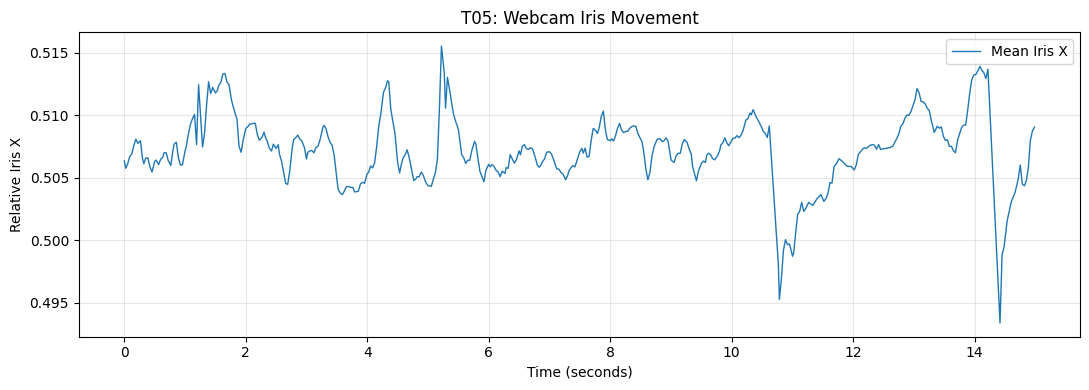

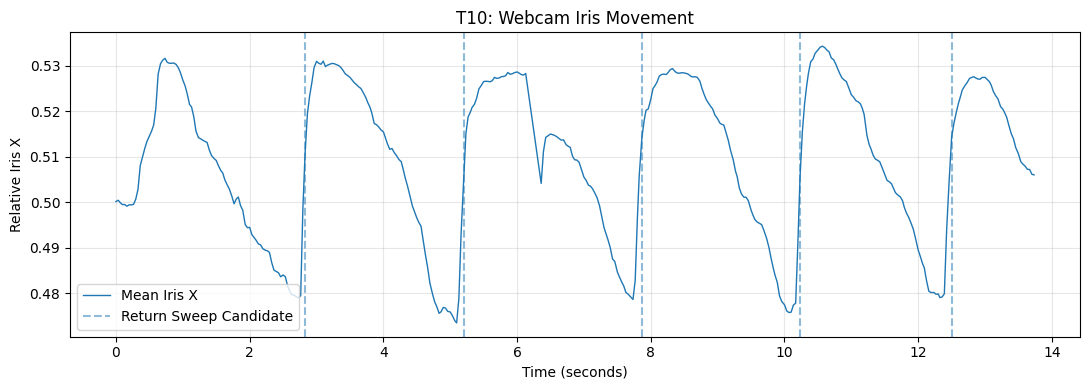

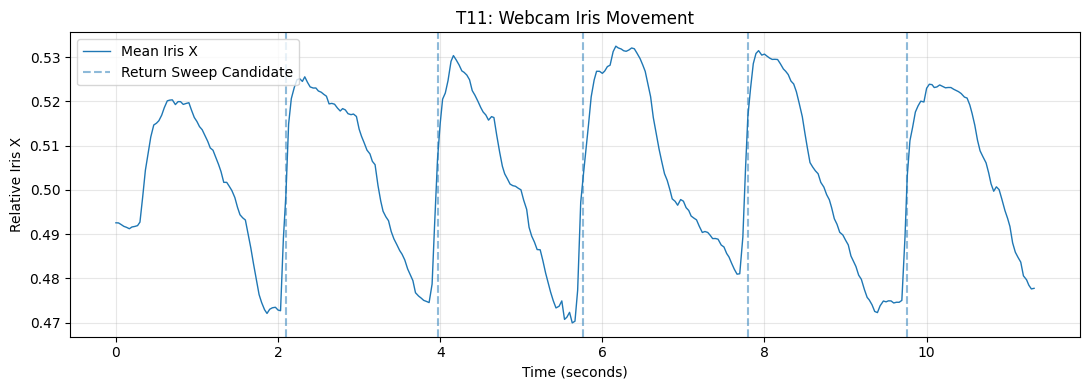

In [ ]:

# STEP 26: 실제 웹캠 홍채 움직임 그래프

import pandas as pd
import matplotlib.pyplot as plt

selected_trials = ["T05", "T10", "T11"]

for tid in selected_trials:

    trial = bundle["trials"][tid]

    samples = trial["samples"].copy()
    events = trial["events"].copy()

    # 유효한 측정값만 사용
    samples = samples[
        (samples["valid"] == True)
        & (samples["in_active_window"] == True)
    ].copy()

    samples["time_s"] = pd.to_numeric(
        samples["time_s"], errors="coerce"
    )

    samples["meanIrisX"] = pd.to_numeric(
        samples["meanIrisX"], errors="coerce"
    )

    samples = samples.dropna(
        subset=["time_s", "meanIrisX"]
    ).sort_values("time_s")

    # 줄바꿈 후보만 추출
    events = events[
        events["type"] == "return_sweep_candidate"
    ].copy()

    events["time_s"] = pd.to_numeric(
        events["time_s"], errors="coerce"
    )

    # 그래프 생성
    plt.figure(figsize=(11, 4))

    plt.plot(
        samples["time_s"],
        samples["meanIrisX"],
        linewidth=1,
        label="Mean Iris X"
    )

    # 줄바꿈 후보가 발생한 시각 표시
    for i, t in enumerate(events["time_s"].dropna()):

        plt.axvline(
            t,
            linestyle="--",
            alpha=0.5,
            label="Return Sweep Candidate" if i == 0 else None
        )

    plt.title(f"{tid}: Webcam Iris Movement")
    plt.xlabel("Time (seconds)")
    plt.ylabel("Relative Iris X")
    plt.legend()
    plt.grid(alpha=0.3)

    plt.tight_layout()
    plt.show()


In [ ]:

# STEP 27: 실제 웹캠 분석 결과 저장

import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

out_dir = Path("analysis/results")
fig_dir = out_dir / "figures"

out_dir.mkdir(parents=True, exist_ok=True)
fig_dir.mkdir(parents=True, exist_ok=True)

selected_trials = ["T05", "T10", "T11"]
rows = []

for tid in selected_trials:

    trial = bundle["trials"][tid]
    samples = trial["samples"].copy()
    events = trial["events"].copy()

    events = events[
        events["type"] == "return_sweep_candidate"
    ].copy()

    for col in ["time_s", "durationMs", "amplitudeX"]:
        events[col] = pd.to_numeric(
            events[col], errors="coerce"
        )

    events = events.sort_values("time_s")

    intervals = events["time_s"].diff().dropna()

    rows.append({
        "trial_id": tid,
        "candidate_count": len(events),
        "mean_interval_s": intervals.mean(),
        "mean_duration_ms": events["durationMs"].mean(),
        "mean_amplitudeX": events["amplitudeX"].mean()
    })

    samples = samples[
        (samples["valid"] == True)
        & (samples["in_active_window"] == True)
    ].copy()

    samples["time_s"] = pd.to_numeric(
        samples["time_s"], errors="coerce"
    )
    samples["meanIrisX"] = pd.to_numeric(
        samples["meanIrisX"], errors="coerce"
    )

    samples = samples.dropna(
        subset=["time_s", "meanIrisX"]
    ).sort_values("time_s")

    fig, ax = plt.subplots(figsize=(10, 4))

    ax.plot(
        samples["time_s"],
        samples["meanIrisX"],
        label="Mean Iris X"
    )

    for i, t in enumerate(events["time_s"].dropna()):
        ax.axvline(
            t,
            linestyle="--",
            alpha=0.5,
            label="Candidate" if i == 0 else None
        )

    ax.set_title(f"{tid}: Webcam Iris Movement")
    ax.set_xlabel("Time (s)")
    ax.set_ylabel("Relative Iris X")
    ax.grid(alpha=0.3)
    ax.legend()

    fig.tight_layout()

    path = fig_dir / f"webcam_{tid}_movement.png"
    fig.savefig(path, dpi=200)
    plt.close(fig)

# 요약표 저장
webcam_df = pd.DataFrame(rows)

csv_path = out_dir / "webcam_behavior_summary.csv"
webcam_df.to_csv(csv_path, index=False)

print("===== 실제 웹캠 분석 결과 =====")
display(webcam_df.round(3))

print("\n저장 완료:")
print(csv_path)

for tid in selected_trials:
    print(fig_dir / f"webcam_{tid}_movement.png")


===== 실제 웹캠 분석 결과 =====


,trial_id,candidate_count,mean_interval_s,mean_duration_ms,mean_amplitudeX
0,T05,0,NaN,NaN,NaN
1,T10,5,2.418,82.56,0.027
2,T11,5,1.916,66.48,0.026



저장 완료:
analysis/results/webcam_behavior_summary.csv
analysis/results/figures/webcam_T05_movement.png
analysis/results/figures/webcam_T10_movement.png
analysis/results/figures/webcam_T11_movement.png


In [ ]:

# STEP 28: 실제 웹캠 분석 결과 ZIP 다운로드

from pathlib import Path
from zipfile import ZipFile, ZIP_DEFLATED
from google.colab import files

file_paths = [
    Path("analysis/results/webcam_behavior_summary.csv"),
    Path("analysis/results/figures/webcam_T05_movement.png"),
    Path("analysis/results/figures/webcam_T10_movement.png"),
    Path("analysis/results/figures/webcam_T11_movement.png")
]

zip_path = Path("B_webcam_analysis_results.zip")

with ZipFile(zip_path, "w", ZIP_DEFLATED) as z:
    for path in file_paths:
        if path.exists():
            z.write(path, arcname=str(path))
            print("추가:", path)
        else:
            print("파일 없음:", path)

print("\n압축 완료:", zip_path)

files.download(str(zip_path))


추가: analysis/results/webcam_behavior_summary.csv
추가: analysis/results/figures/webcam_T05_movement.png
추가: analysis/results/figures/webcam_T10_movement.png
추가: analysis/results/figures/webcam_T11_movement.png

압축 완료: B_webcam_analysis_results.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

T05 center_fixation 


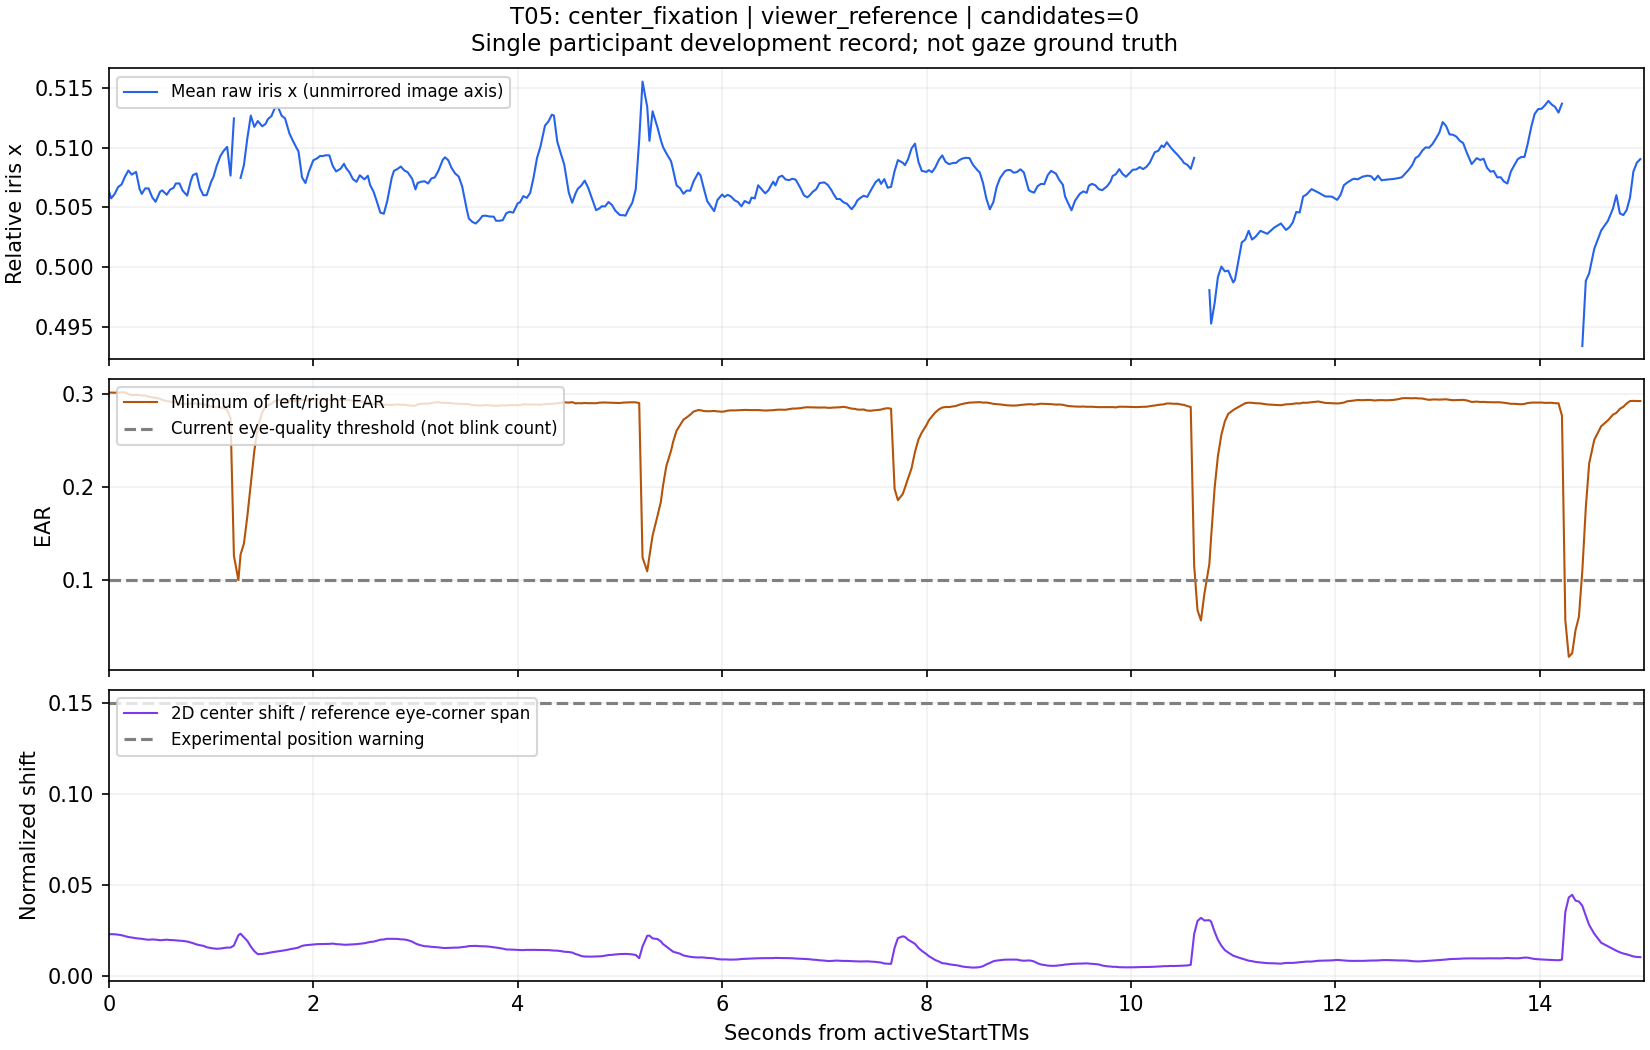

T06 natural_reading 


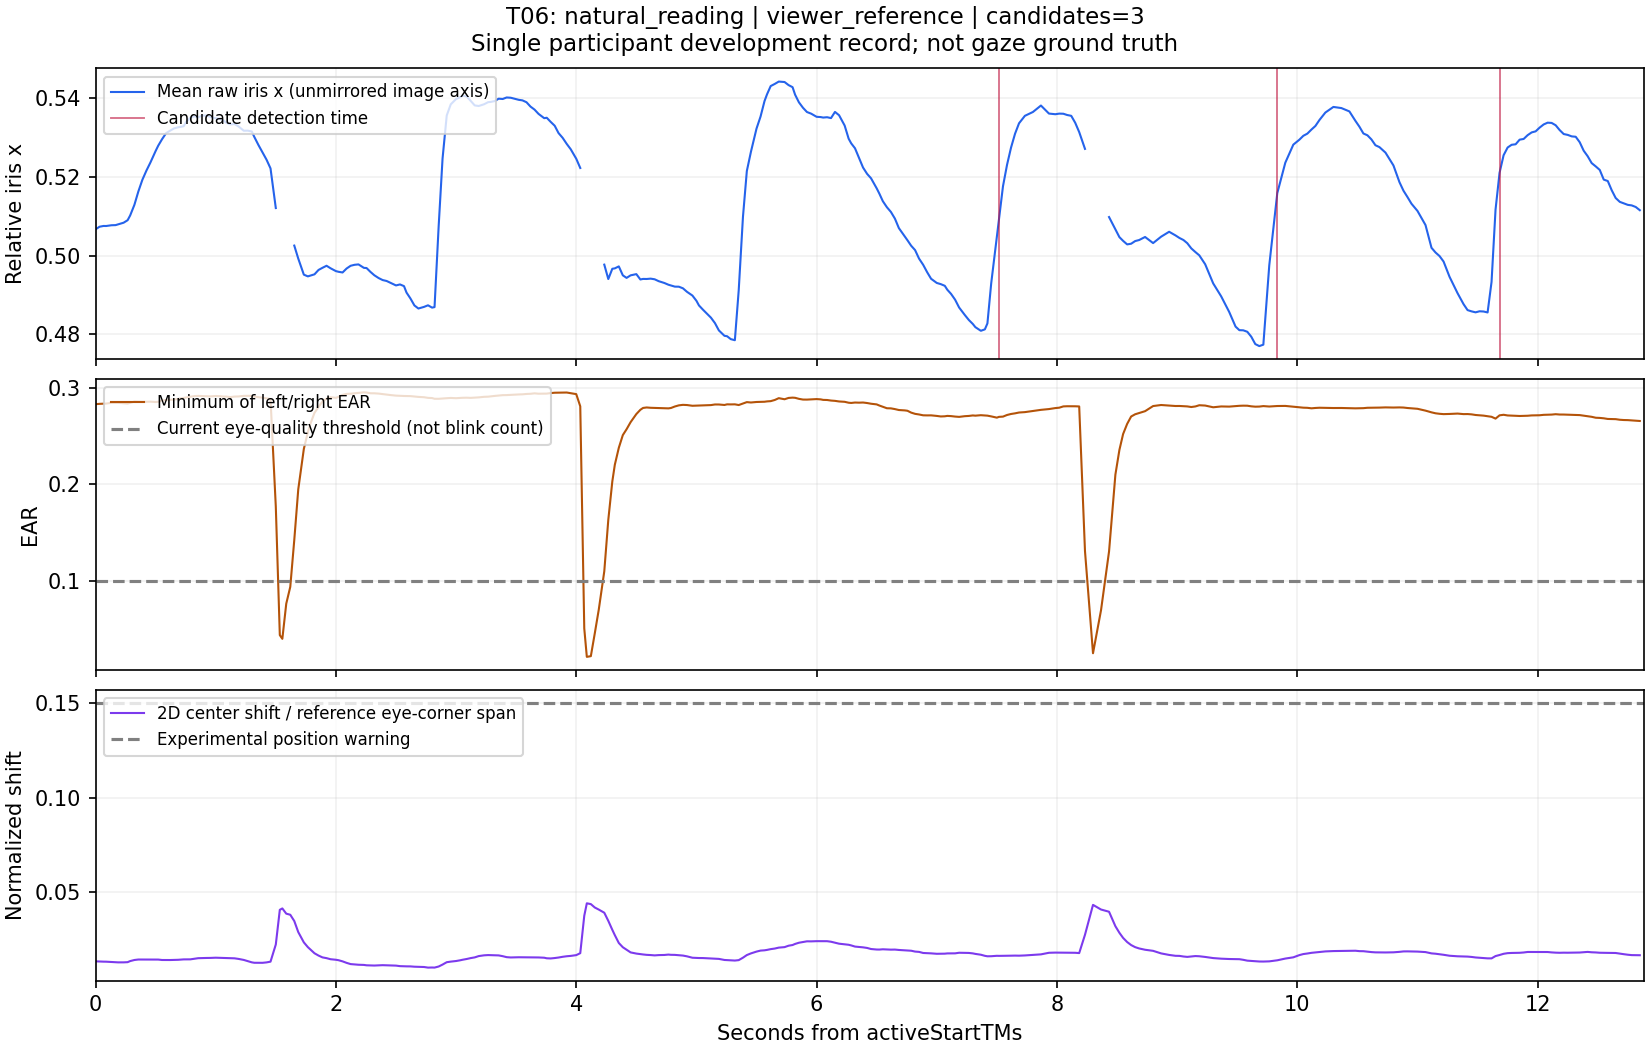

T07 line_marked_reading 키 입력이 읽기 동작에 영향을 줄 수 있음. 키 시점은 시선 정답이 아님.


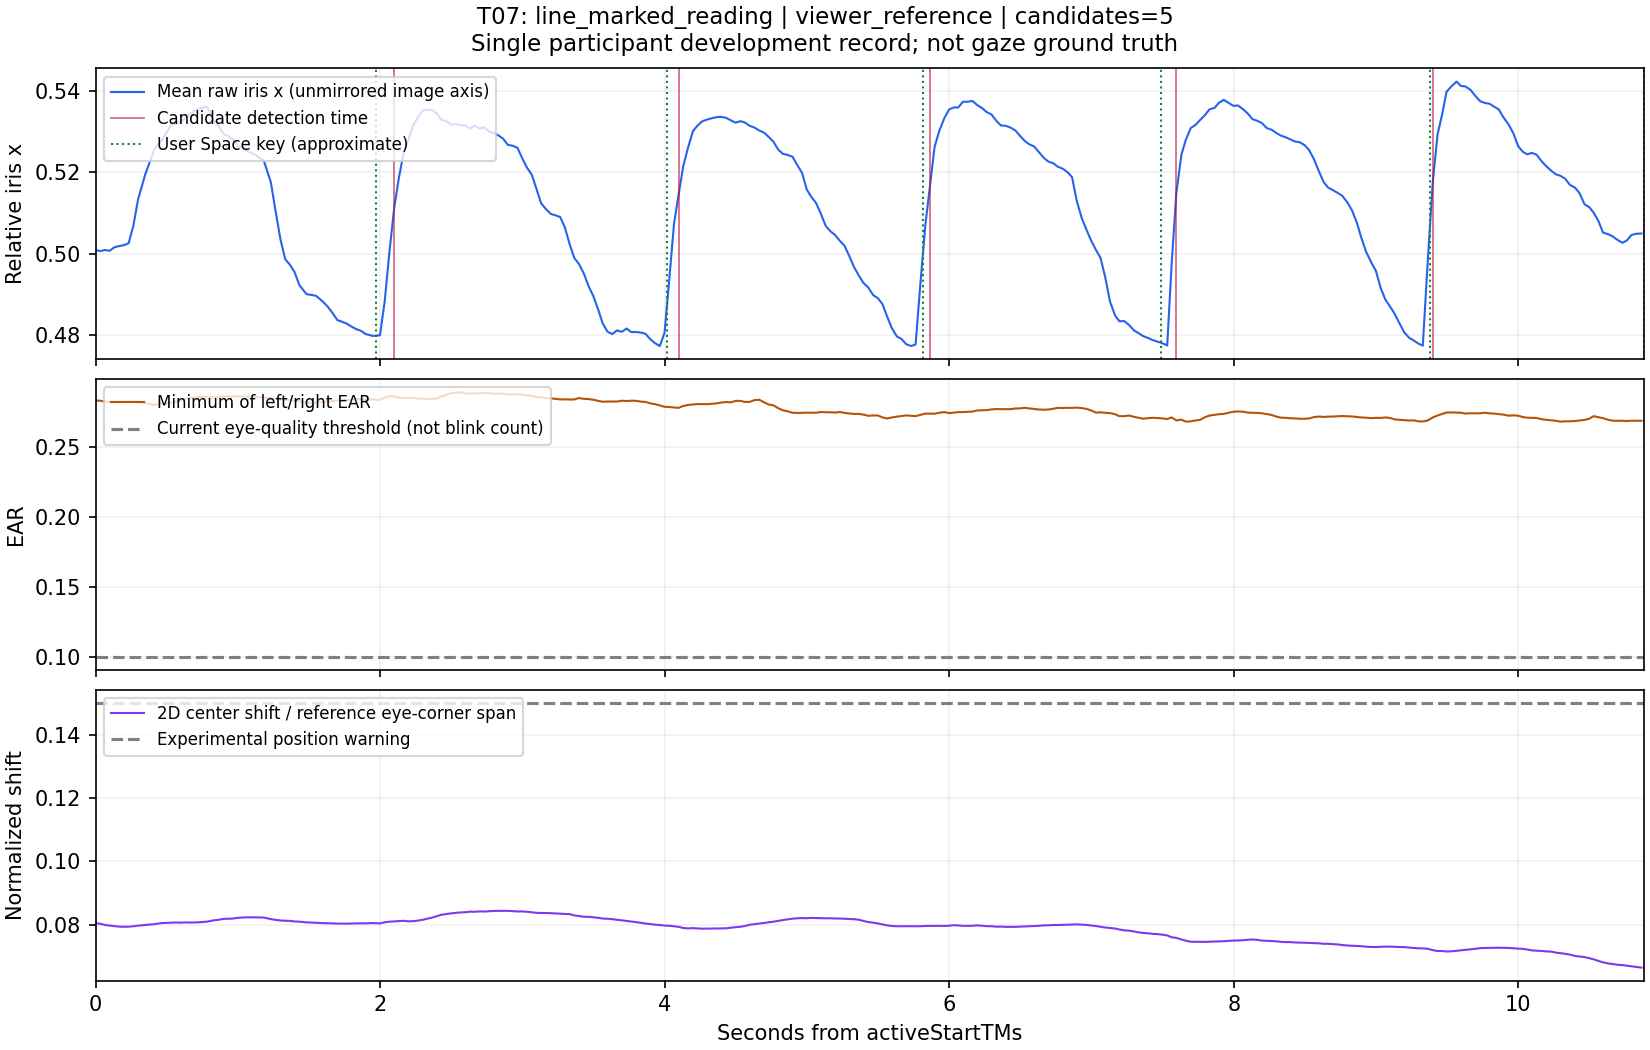

T08 natural_reading 기준 대비 자세 경고가 읽기 내내 발생. 기준은 같지만 자세가 동일하지 않음.


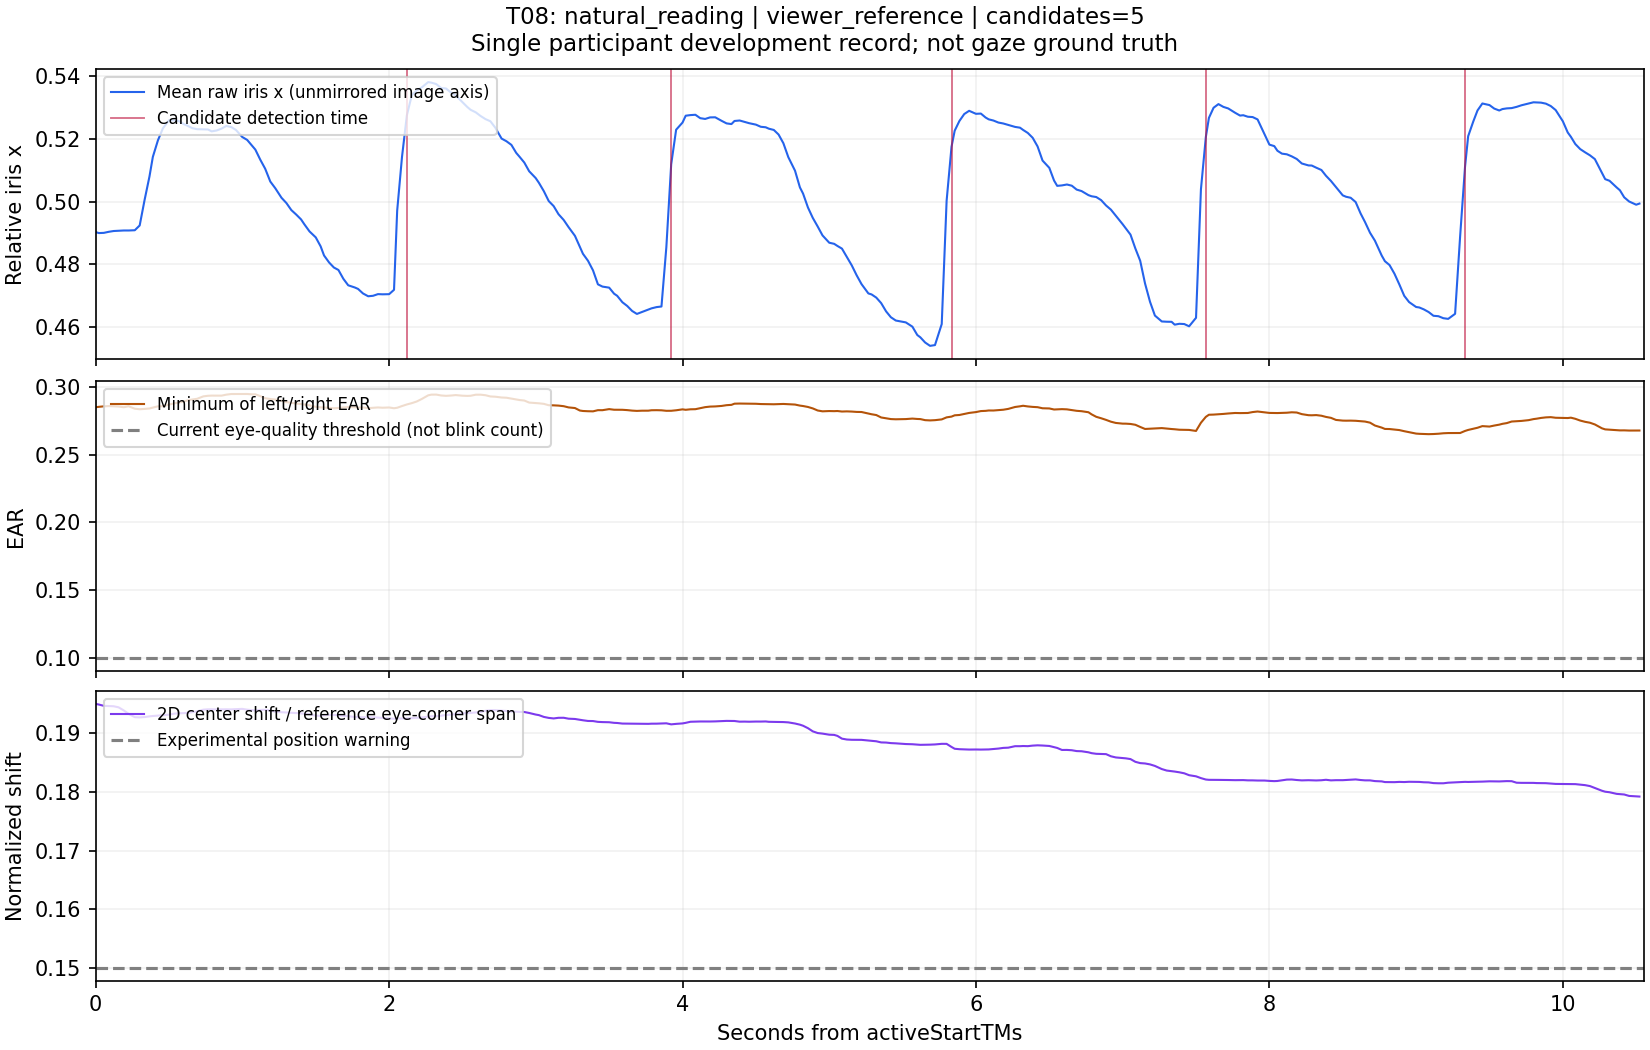

T10 natural_reading 


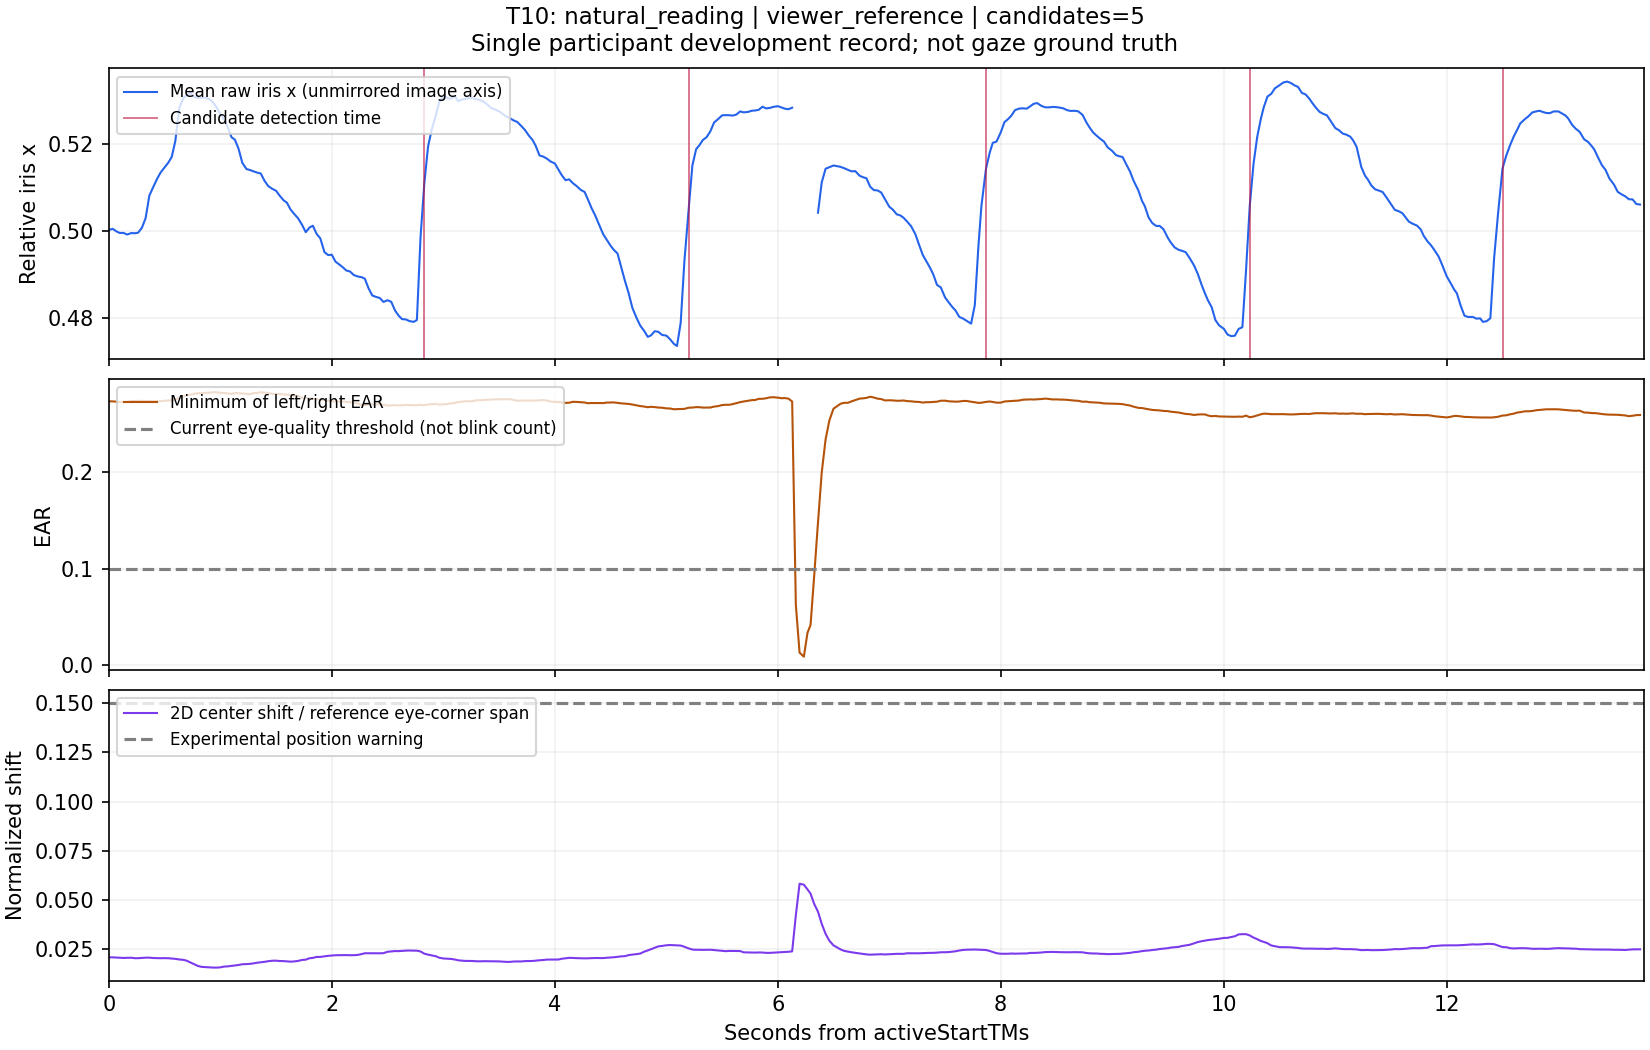

T11 reread_first3_twice 앞 3줄 두 번 읽기 안내 직후 제출. 별도 행동 확인 문장은 없음. 실제 읽은 줄의 시선 정답은 없음.


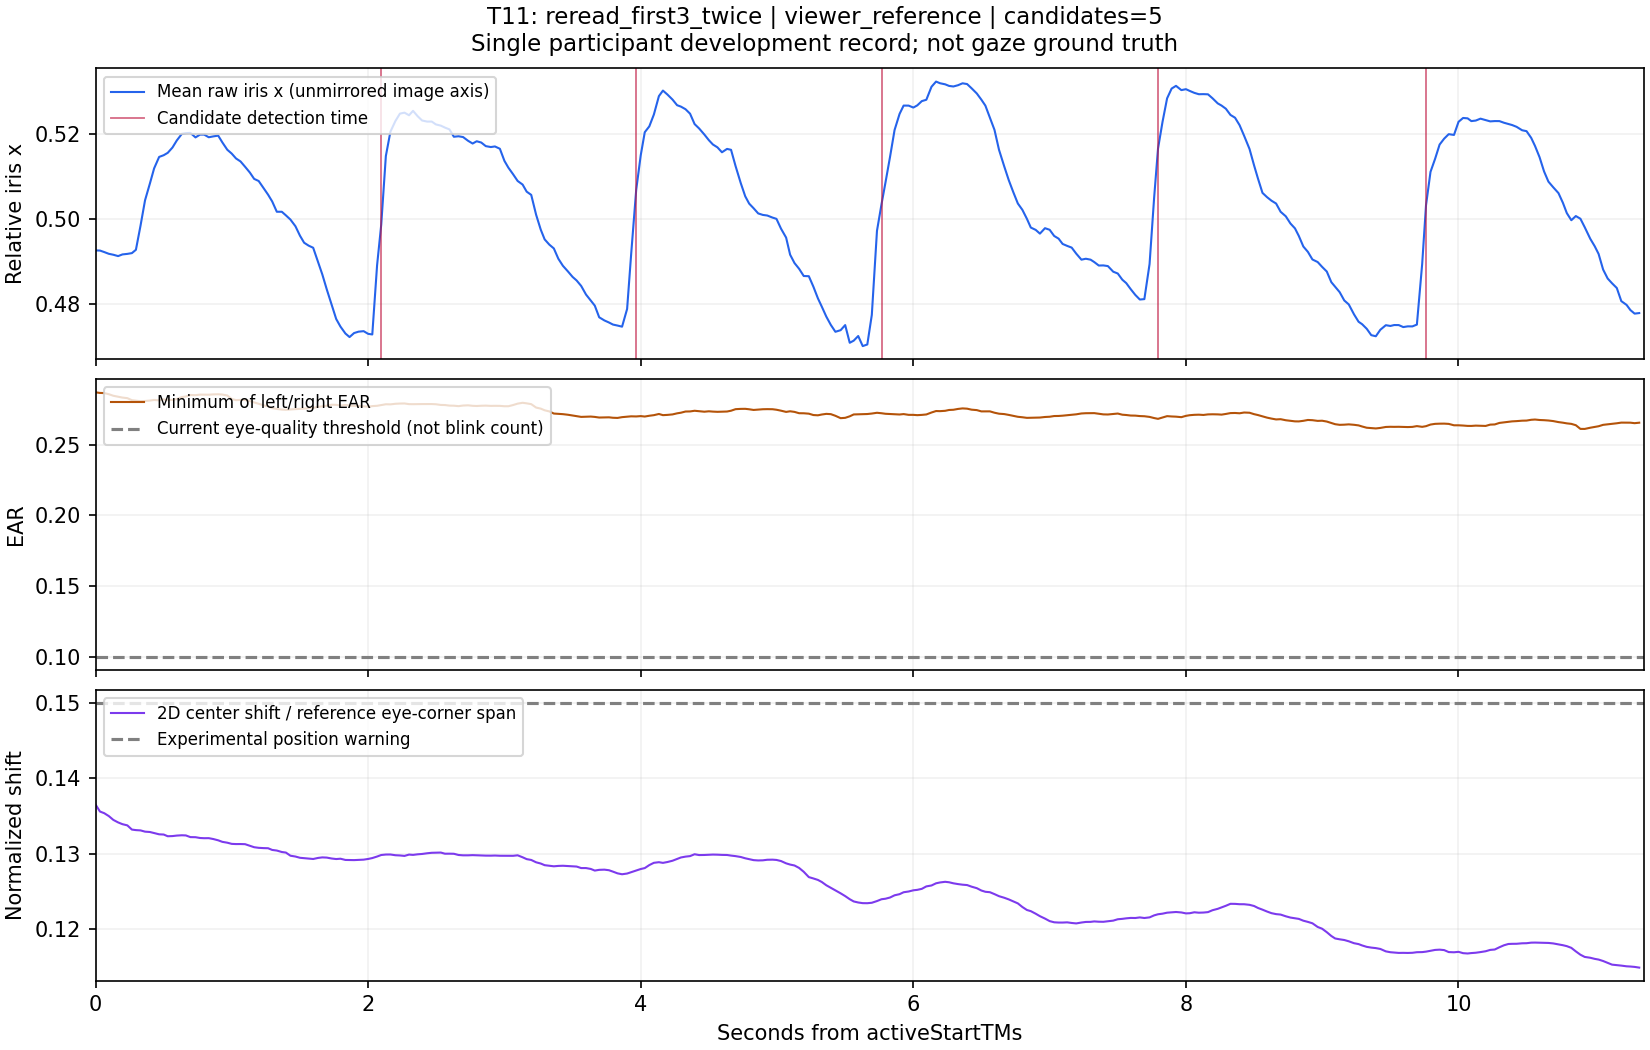

In [ ]:
# 파일의 active 시간 창과 raw CSV, 그림을 함께 확인합니다.
from PIL import Image
for trial_id in ['T05', 'T06', 'T07', 'T08', 'T10', 'T11']:
    metadata = bundle['trials'][trial_id]['metadata']
    print(trial_id, metadata['behavior_instruction'], metadata['specific_caveat'])
    with Image.open(ROOT / 'plots' / (trial_id + '_' + metadata['behavior_instruction'] + '.png')) as image:
        display(image.copy())


## 다음 분석 시 주의

공개 데이터의 화면 x·y와 이 자료의 홍채 상대 x는 다른 물리량입니다. 샘플 간 이동량은 처리 빈도·잡음에 영향을 받습니다. 단위·유효 구간·측정 빈도를 먼저 비교하세요. T10과 T11 후보 수가 같은 것은 재독의 한계 사례이며 읽기 정확도 100%의 근거가 아닙니다. T11 행동은 안내를 따른 것으로 간주한 개발 기록이며 별도 시선 정답은 없습니다. 다음 A 작업은 상하 위치 구분 시험 준비이며 아직 새 y 측정 결과는 없습니다.
